# Stochastic Simulation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/caam37830-sci-comp/notes/blob/main/07_probability_statistics/stochastic_simulation.ipynb)

In [Monte Carlo Methods](monte_carlo.ipynb), randomness was a tool for computing a fixed
number.  In this section randomness is part of the model: particles diffusing in a fluid,
a noisy physical system, an epidemic spreading through a small population.  We simulate
many random trajectories, called **sample paths**, and study their statistics.

Throughout, we draw random numbers from a seeded `Generator`, so that every run of the
notebook gives the same results (see [Generating Random Numbers](generating_random.ipynb)).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq

rng = np.random.default_rng(37830)

## Random walks and diffusion

A **simple random walk** starts at 0 and moves one step left or right with equal
probability at each time.  NumPy simulates many independent walkers at once: draw a matrix
of $\pm 1$ steps, one row per walker, and take cumulative sums along the rows.

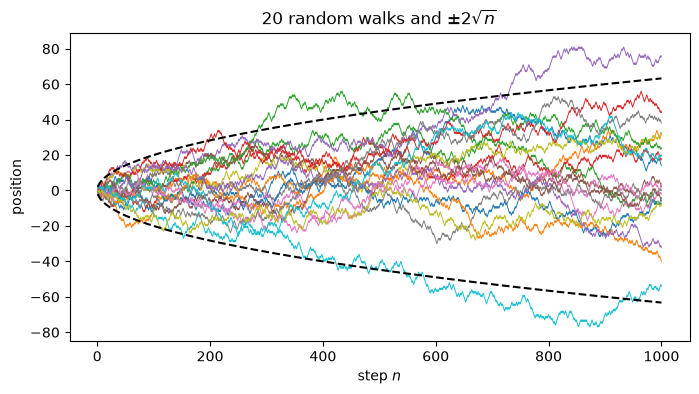

after   10 steps: mean  +0.01, variance    10.2
after  100 steps: mean  +0.14, variance   100.4
after 1000 steps: mean  +0.48, variance  1001.6


In [2]:
walkers, steps = 10_000, 1000
X = np.cumsum(rng.choice([-1, 1], size=(walkers, steps)), axis=1)

n = np.arange(1, steps + 1)
plt.figure(figsize=(8, 4))
plt.plot(n, X[:20].T, lw=0.7)
plt.plot(n, 2 * np.sqrt(n), 'k--', n, -2 * np.sqrt(n), 'k--')
plt.xlabel('step $n$')
plt.ylabel('position')
plt.title(r'20 random walks and $\pm 2\sqrt{n}$')
plt.show()

for k in [10, 100, 1000]:
    print(f"after {k:4d} steps: mean {X[:, k - 1].mean():+6.2f}, variance {X[:, k - 1].var():7.1f}")

The steps are independent with mean 0 and variance 1, so after $n$ steps the position has
mean 0 and variance $n$: a typical walker is about $\sqrt n$ from the start.

Now shrink the steps.  Move by $\pm\Delta x$ every $\Delta t$, with
$\Delta x^2 = 2D\,\Delta t$ for a constant $D$.  At time $t$ the position has variance
$(t/\Delta t)\,\Delta x^2 = 2Dt$, and by the central limit theorem it is approximately
normal.  Its density is therefore

$$ u(x, t) = \frac{1}{\sqrt{4\pi D t}}\, e^{-x^2/(4Dt)}, $$

the **heat kernel**, the solution of the diffusion equation $u_t = D u_{xx}$ that starts
from a point source.  The diffusion equation of
[Time-Dependent PDEs](../05_differential_equations/pde_time_evolution.ipynb) describes the
density of a cloud of random walkers.

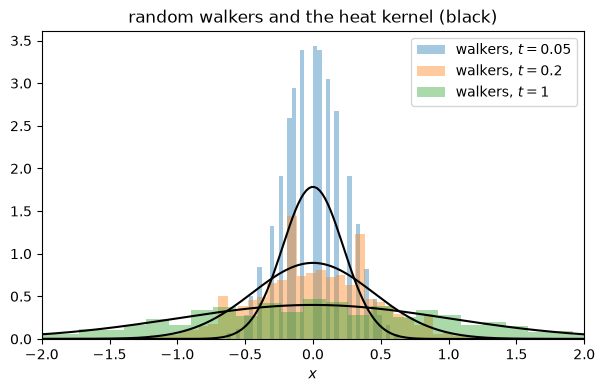

In [3]:
D, dt = 0.5, 1e-3
dx = np.sqrt(2 * D * dt)
positions = dx * X                       # the same walks, with steps of size dx every dt

x = np.linspace(-3, 3, 300)
plt.figure(figsize=(7, 4))
for k in [50, 200, 1000]:
    t = k * dt
    plt.hist(positions[:, k - 1], bins=50, density=True, alpha=0.4, label=f'walkers, $t = {t:g}$')
    plt.plot(x, np.exp(-x**2 / (4 * D * t)) / np.sqrt(4 * np.pi * D * t), 'k')
plt.xlim(-2, 2)
plt.xlabel('$x$')
plt.legend()
plt.title('random walkers and the heat kernel (black)')
plt.show()

## Brownian motion and stochastic differential equations

The limit of the scaled random walk (with $D = 1/2$) is **Brownian motion** $W(t)$: it
starts at $W(0) = 0$, and its increments over disjoint time intervals are independent with

$$ W(t + \Delta t) - W(t) \sim \mathcal N(0, \Delta t). $$

The increment over a step $\Delta t$ is of size $\sqrt{\Delta t}$, much larger than
$\Delta t$ when the step is small.  Brownian paths are continuous but nowhere
differentiable, so a noisy ODE can't be written with $dW/dt$.  Instead we write a
**stochastic differential equation (SDE)**

$$ dX = a(X, t)\, dt + b(X, t)\, dW, $$

with a deterministic **drift** $a$ and a **diffusion** coefficient $b$ that scales the
noise.  The simplest numerical method is **Euler-Maruyama**, forward Euler with a random
increment added at each step:

$$ X_{n+1} = X_n + a(X_n, t_n)\,\Delta t + b(X_n, t_n)\,\Delta W_n, \qquad
\Delta W_n = \sqrt{\Delta t}\;\xi_n, \quad \xi_n \sim \mathcal N(0, 1). $$

In [4]:
def euler_maruyama(a, b, x0, T, nsteps, npaths, rng):
    """
    Euler-Maruyama for dX = a(X, t) dt + b(X, t) dW, simulating npaths paths at once

    returns times t (nsteps + 1,) and paths X (npaths, nsteps + 1)
    """
    dt = T / nsteps
    t = dt * np.arange(nsteps + 1)
    X = np.empty((npaths, nsteps + 1))
    X[:, 0] = x0
    for n in range(nsteps):
        dW = np.sqrt(dt) * rng.standard_normal(npaths)
        X[:, n + 1] = X[:, n] + a(X[:, n], t[n]) * dt + b(X[:, n], t[n]) * dW
    return t, X

### Example: the Ornstein-Uhlenbeck process

$$ dX = -\theta X\, dt + \sigma\, dW $$

is the simplest SDE with interesting behavior: the drift pulls $X$ back toward 0 while the
noise kicks it around.  It models, for example, the velocity of a particle in a fluid,
slowed down by friction and pushed by molecular collisions.  The mean decays like
$X_0 e^{-\theta t}$, and in the long run $X$ settles into a stationary distribution, the
normal distribution with variance $\sigma^2/(2\theta)$.

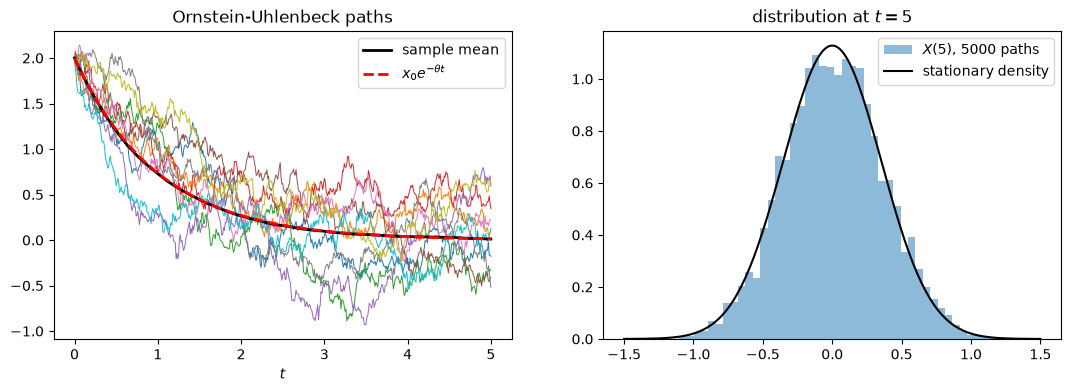

sample variance at t = 5: 0.1268, stationary variance sigma^2 / (2 theta) = 0.1250


In [5]:
theta, sigma, x0 = 1.0, 0.5, 2.0
t, X = euler_maruyama(lambda x, t: -theta * x, lambda x, t: sigma,
                      x0, T=5.0, nsteps=500, npaths=5000, rng=rng)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(t, X[:10].T, lw=0.7)
ax[0].plot(t, X.mean(axis=0), 'k', lw=2, label='sample mean')
ax[0].plot(t, x0 * np.exp(-theta * t), 'r--', lw=2, label=r'$x_0 e^{-\theta t}$')
ax[0].set_xlabel('$t$')
ax[0].legend()
ax[0].set_title('Ornstein-Uhlenbeck paths')

stationary = stats.norm(0, sigma / np.sqrt(2 * theta))
xs = np.linspace(-1.5, 1.5, 200)
ax[1].hist(X[:, -1], bins=50, density=True, alpha=0.5, label='$X(5)$, 5000 paths')
ax[1].plot(xs, stationary.pdf(xs), 'k', label='stationary density')
ax[1].legend()
ax[1].set_title('distribution at $t = 5$')
plt.show()

print(f"sample variance at t = 5: {X[:, -1].var():.4f}, "
      f"stationary variance sigma^2 / (2 theta) = {sigma**2 / (2 * theta):.4f}")

### How accurate is Euler-Maruyama?

For SDEs there are two different questions, and they have different answers.

* **Strong error**, $\mathbb E\,|X_N - X(T)|$, asks how close the computed path is to the
  exact path *driven by the same Brownian motion*.  Euler-Maruyama has strong order 1/2.
* **Weak error**, $|\mathbb E f(X_N) - \mathbb E f(X(T))|$, only asks about statistics
  of the solution, such as its mean or variance.  Euler-Maruyama has weak order 1.

Most applications need only weak accuracy.  To measure either we need an exact solution.
**Geometric Brownian motion**, the standard model for a stock price,

$$ dS = \mu S\, dt + \sigma S\, dW, $$

has the exact solution

$$ S(t) = S_0 \exp\!\left( \left(\mu - \tfrac{\sigma^2}{2}\right) t + \sigma W(t) \right). $$

The $-\sigma^2/2$ is not a typo.  It comes from Itô's formula, the chain rule of stochastic
calculus, which has an extra second-order term because $(dW)^2$ behaves like $dt$.
Dropping it is a classic bug.

To measure the strong error, the coarse and the exact solution must see the same Brownian
path.  We generate the increments on a fine grid and add them up in blocks to get the
increments for each coarser step.

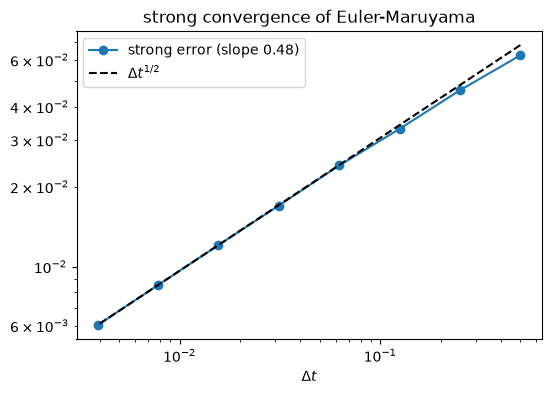

In [6]:
mu, sigma, S0, T = 0.05, 0.4, 1.0, 1.0
npaths, nfine = 10_000, 2**9
dW_fine = np.sqrt(T / nfine) * rng.standard_normal((npaths, nfine))
S_exact = S0 * np.exp((mu - sigma**2 / 2) * T + sigma * dW_fine.sum(axis=1))

nsteps_list = 2 ** np.arange(1, 9)
strong = []
for m in nsteps_list:
    dW = dW_fine.reshape(npaths, m, nfine // m).sum(axis=2)   # same path, coarser steps
    S = np.full(npaths, S0)
    for j in range(m):
        S = S + mu * S * (T / m) + sigma * S * dW[:, j]
    strong.append(np.mean(np.abs(S - S_exact)))

dts = T / nsteps_list
order = np.polyfit(np.log(dts), np.log(strong), 1)[0]
plt.figure(figsize=(6, 4))
plt.loglog(dts, strong, 'o-', label=f'strong error (slope {order:.2f})')
plt.loglog(dts, strong[-1] * np.sqrt(dts / dts[-1]), 'k--', label=r'$\Delta t^{1/2}$')
plt.xlabel(r'$\Delta t$')
plt.legend()
plt.title('strong convergence of Euler-Maruyama')
plt.show()

For the weak error we don't need matching paths, only an exact expectation.  For geometric
Brownian motion $\mathbb E[S(T)^2] = S_0^2\, e^{(2\mu + \sigma^2)T}$.  We estimate
$\mathbb E[S_N^2]$ from a million independent paths and show the Monte Carlo uncertainty
(two standard errors) with error bars.

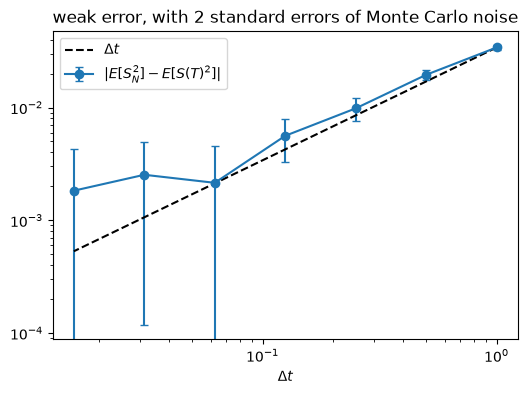

In [7]:
exact_second_moment = S0**2 * np.exp((2 * mu + sigma**2) * T)
npaths = 10**6
nsteps_list = 2 ** np.arange(0, 7)
bias, half_width = [], []
for m in nsteps_list:
    S = np.full(npaths, S0)
    for _ in range(m):
        S += mu * S * (T / m) + sigma * S * np.sqrt(T / m) * rng.standard_normal(npaths)
    bias.append(abs(np.mean(S**2) - exact_second_moment))
    half_width.append(2 * np.std(S**2) / np.sqrt(npaths))

dts = T / nsteps_list
plt.figure(figsize=(6, 4))
plt.errorbar(dts, bias, yerr=half_width, fmt='o-', capsize=3, label=r'$|E[S_N^2] - E[S(T)^2]|$')
plt.loglog(dts, bias[0] * dts / dts[0], 'k--', label=r'$\Delta t$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\Delta t$')
plt.legend()
plt.title('weak error, with 2 standard errors of Monte Carlo noise')
plt.show()

The weak error decreases like $\Delta t$ until it meets the Monte Carlo noise, after which
the estimate is just noise.  A bias smaller than the statistical error is invisible.  To
cut the total error of a weak estimate in half you must halve $\Delta t$ *and* use four
times as many paths, so the cost grows like $\varepsilon^{-3}$ for accuracy $\varepsilon$.
Balancing the two sources of error is the central practical problem in this area, and
methods such as multilevel Monte Carlo were invented to beat this cost.

## Langevin dynamics as a sampler

The **overdamped Langevin equation**

$$ dX = -V'(X)\, dt + \sqrt{2/\beta}\; dW $$

describes a particle sliding downhill on a potential $V$ while being kicked by thermal
noise at inverse temperature $\beta$.  Its stationary distribution is the Boltzmann
distribution with density proportional to $e^{-\beta V(x)}$.  This is the same kind of
target as in the MCMC example of [Monte Carlo Methods](monte_carlo.ipynb), and simulating
Langevin dynamics is another way to sample from it.

Take the double well $V(x) = (x^2 - 1)^2$, with minima at $\pm 1$ and a barrier of height 1
between them, and run ten thousand particles to $t = 30$.

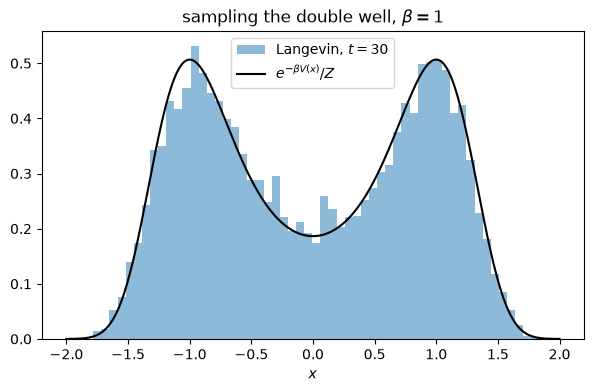

E[X^2]: Langevin 0.8184, exact 0.8327


In [8]:
V = lambda x: (x**2 - 1)**2
dV = lambda x: 4 * x * (x**2 - 1)

beta, dt = 1.0, 0.01
Xw = rng.choice([-1.0, 1.0], size=10_000)
for _ in range(3000):
    Xw = Xw - dV(Xw) * dt + np.sqrt(2 * dt / beta) * rng.standard_normal(Xw.size)

Z = quad(lambda x: np.exp(-beta * V(x)), -np.inf, np.inf)[0]
xs = np.linspace(-2, 2, 300)
plt.figure(figsize=(7, 4))
plt.hist(Xw, bins=60, density=True, alpha=0.5, label='Langevin, $t = 30$')
plt.plot(xs, np.exp(-beta * V(xs)) / Z, 'k', label=r'$e^{-\beta V(x)} / Z$')
plt.xlabel('$x$')
plt.legend()
plt.title(r'sampling the double well, $\beta = 1$')
plt.show()

exact_x2 = quad(lambda x: x**2 * np.exp(-beta * V(x)), -np.inf, np.inf)[0] / Z
print(f"E[X^2]: Langevin {np.mean(Xw**2):.4f}, exact {exact_x2:.4f}")

The match is good but not perfect: Euler-Maruyama samples a distribution that differs from
the true one by $O(\Delta t)$.  Adding a Metropolis accept/reject step to each Langevin
move removes this bias, and the resulting method (MALA) is a standard MCMC algorithm.

**Metastability.**  At low temperature (large $\beta$) a particle spends long stretches in
one well before a rare large kick carries it over the barrier.  The rate of these
transitions falls off like $e^{-\beta\,\Delta V}$, where $\Delta V$ is the barrier height.

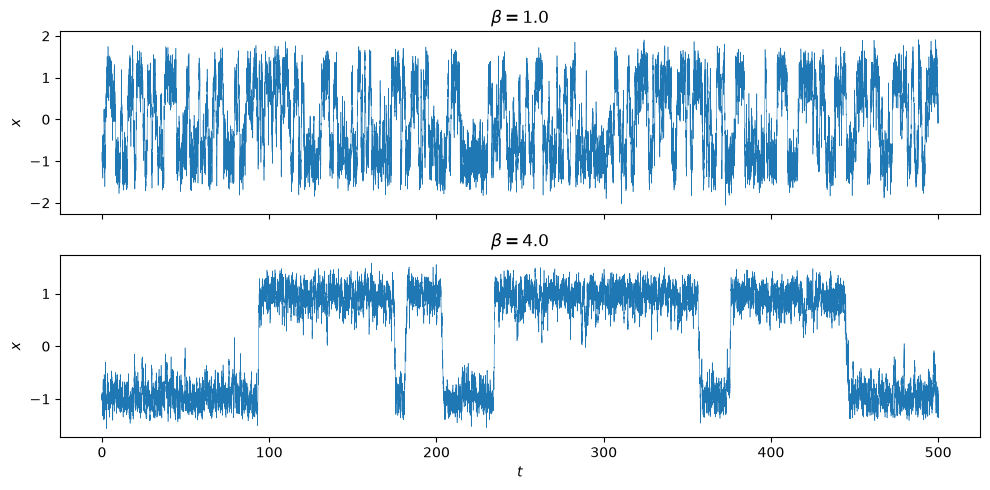

In [9]:
def langevin_path(beta, x0, dt, nsteps, rng):
    """
    one Euler-Maruyama path of the overdamped Langevin equation in the double well
    """
    x = np.empty(nsteps + 1)
    x[0] = x0
    noise = np.sqrt(2 * dt / beta) * rng.standard_normal(nsteps)
    for n in range(nsteps):
        x[n + 1] = x[n] - dV(x[n]) * dt + noise[n]
    return x


dt, nsteps = 0.01, 50_000
t = dt * np.arange(nsteps + 1)
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for a, b in zip(ax, [1.0, 4.0]):
    a.plot(t, langevin_path(b, -1.0, dt, nsteps, rng), lw=0.4)
    a.set_ylabel('$x$')
    a.set_title(f'$\\beta = {b}$')
ax[1].set_xlabel('$t$')
plt.tight_layout()
plt.show()

At $\beta = 4$ the particle hops only a handful of times in 500 time units.  An average
computed from this path converges slowly, because the path needs many hops to learn the
relative weights of the two wells.  The same problem afflicts MCMC, and much of the work on
sampling algorithms is about getting across barriers faster.

## Discrete stochastic models: the Gillespie algorithm

When the number of individuals is small, randomness in *when* individual events happen
matters.  Consider an epidemic in a population of $N$ people, divided into susceptible
($S$), infected ($I$), and recovered ($R$).  Two kinds of events happen:

* **infection**, $S + I \to 2I$, at rate $\beta S I / N$;
* **recovery**, $I \to R$, at rate $\gamma I$.

Treating the counts as continuous gives the SIR model of ODEs,

$$ S' = -\beta S I/N, \qquad I' = \beta S I / N - \gamma I, \qquad R' = \gamma I. $$

**Gillespie's algorithm** simulates the random events exactly.  If the events have rates
("propensities") $a_1, \dots, a_m$ with total $a_0 = \sum_j a_j$, then the waiting time
until the next event is exponentially distributed with rate $a_0$, and the event is of
type $j$ with probability $a_j / a_0$.  Draw both, update the state, and repeat.  There is
no time step, so there is no discretization error.

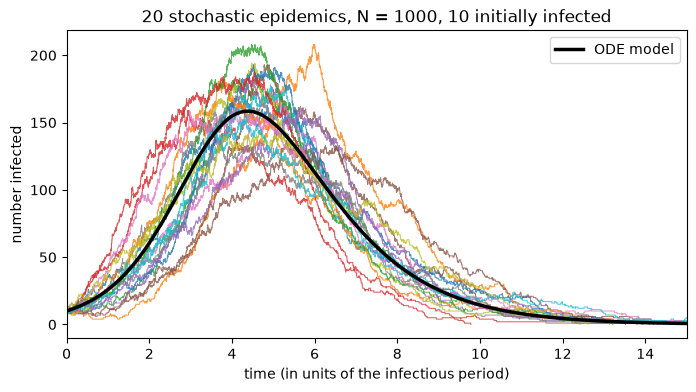

In [10]:
def gillespie_sir(N, I0, beta, gamma, rng):
    """
    exact stochastic simulation of the SIR model until the epidemic dies out

    returns event times, the number infected after each event, and the final number recovered
    """
    S, I, R = N - I0, I0, 0
    t = 0.0
    times, infected = [0.0], [I0]
    while I > 0:
        a_infect = beta * S * I / N
        a_recover = gamma * I
        a_total = a_infect + a_recover
        t += rng.exponential(1 / a_total)          # waiting time to the next event
        if rng.random() * a_total < a_infect:      # which event happened
            S, I = S - 1, I + 1
        else:
            I, R = I - 1, R + 1
        times.append(t)
        infected.append(I)
    return np.array(times), np.array(infected), R


N, beta, gamma = 1000, 2.0, 1.0
ode = solve_ivp(lambda t, y: [-beta * y[0] * y[1] / N, beta * y[0] * y[1] / N - gamma * y[1]],
                (0, 15), [N - 10, 10], t_eval=np.linspace(0, 15, 300), rtol=1e-8)

plt.figure(figsize=(8, 4))
for _ in range(20):
    times, infected, _ = gillespie_sir(N, 10, beta, gamma, rng)
    plt.step(times, infected, where='post', lw=0.7, alpha=0.8)
plt.plot(ode.t, ode.y[1], 'k', lw=2.5, label='ODE model')
plt.xlim(0, 15)
plt.xlabel('time (in units of the infectious period)')
plt.ylabel('number infected')
plt.legend()
plt.title('20 stochastic epidemics, N = 1000, 10 initially infected')
plt.show()

The stochastic epidemics have the same shape as the ODE solution but peak at random times,
because the early phase, when only a few people are infected, is dominated by chance.

Starting from a single infected person, chance can end the epidemic right away.  Early on,
the epidemic is a **branching process** in which each infected person infects others at
rate $\beta$ and recovers at rate $\gamma$.  The theory of branching processes says that
the probability that it dies out before becoming a major outbreak is $1/R_0$, where
$R_0 = \beta/\gamma$ is the basic reproduction number.  If it does take off, the fraction
$z$ of the population eventually infected solves the **final size equation**
$z = 1 - e^{-R_0 z}$.  We check both.

1000 epidemics simulated in 0.23 s
fraction that died out early: 0.480   (theory 1/R0 = 0.500)
mean final size of major outbreaks: 0.794   (final size equation: 0.797)


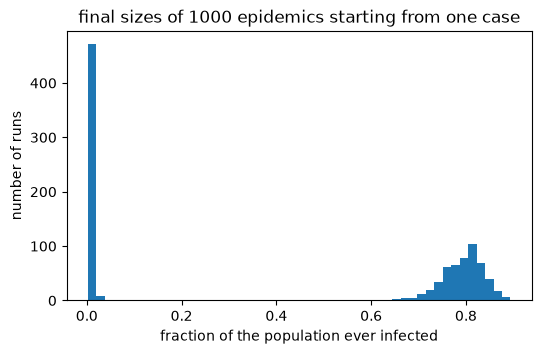

In [11]:
N, runs = 500, 1000
start = time.perf_counter()
final_sizes = np.array([gillespie_sir(N, 1, beta, gamma, rng)[2] for _ in range(runs)])
elapsed = time.perf_counter() - start

R0 = beta / gamma
minor = final_sizes < 0.1 * N
z = brentq(lambda z: z - 1 + np.exp(-R0 * z), 1e-6, 1)

print(f"{runs} epidemics simulated in {elapsed:.2f} s")
print(f"fraction that died out early: {minor.mean():.3f}   (theory 1/R0 = {1 / R0:.3f})")
print(f"mean final size of major outbreaks: {final_sizes[~minor].mean() / N:.3f}   "
      f"(final size equation: {z:.3f})")

plt.figure(figsize=(6, 3.5))
plt.hist(final_sizes / N, bins=50)
plt.xlabel('fraction of the population ever infected')
plt.ylabel('number of runs')
plt.title('final sizes of 1000 epidemics starting from one case')
plt.show()

Both predictions hold up.  The distribution of final sizes is bimodal: an epidemic either
fizzles out after a few cases or infects about 80% of the population.  The ODE model, which
predicts a major outbreak every time, misses the first possibility entirely.

The Gillespie algorithm assumes a well-mixed population, in which everybody is equally
likely to meet everybody else.  [Agent-Based Models](../10_computing/agent_based_models.ipynb)
drop that assumption and track individuals with their own positions, contacts, or
behaviors.

## Exercises

### Exercise 1

Simulate 5000 random walks in two dimensions, with independent normal steps of variance
$2D\Delta t$ in each coordinate.  Plot the mean squared distance from the origin against
time and compare with $4Dt$.  Then estimate the distribution of the first time a walker
reaches distance 1 from the origin.

In [12]:
# Your code here

### Exercise 2

For the Ornstein-Uhlenbeck process, show that Euler-Maruyama has stationary variance
$\sigma^2 / (2\theta - \theta^2 \Delta t)$ instead of $\sigma^2/(2\theta)$, and check it
numerically for $\theta\Delta t = 0.1, 0.5, 1$.  Then show that the update

$$ X_{n+1} = e^{-\theta\Delta t} X_n + \sigma \sqrt{\frac{1 - e^{-2\theta\Delta t}}{2\theta}}\;\xi_n $$

reproduces the exact distribution of the process for any $\Delta t$, and verify this
numerically too.

In [13]:
# Your code here

### Exercise 3

The **Milstein method** adds a correction term to Euler-Maruyama:

$$ X_{n+1} = X_n + a\,\Delta t + b\,\Delta W_n + \tfrac12\, b\, b'\,\left(\Delta W_n^2 - \Delta t\right), $$

where $b' = \partial b/\partial x$.  Implement it for geometric Brownian motion and show
that its strong order is 1.

In [14]:
# Your code here

### Exercise 4

A European call option pays $\max(S(T) - K, 0)$ at time $T$.  With a stock that follows
geometric Brownian motion with $\mu = r$, its price is $e^{-rT}\,\mathbb E[\max(S(T)-K, 0)]$.
Estimate the price by Monte Carlo for $S_0 = K = 1$, $r = 0.03$, $\sigma = 0.2$, $T = 1$,
sampling $S(T)$ directly from the exact solution.  Compare with the Black-Scholes formula

$$ C = S_0\, \Phi(d_1) - K e^{-rT}\, \Phi(d_2), \qquad
d_{1,2} = \frac{\log(S_0/K) + (r \pm \sigma^2/2)T}{\sigma\sqrt T}, $$

where $\Phi$ is `stats.norm.cdf`, and plot the error against the number of samples.  Then
use **antithetic variates** (pair each $\xi$ with $-\xi$) and measure how much the variance
drops.

In [15]:
# Your code here

### Exercise 5

Plot the probability of a major outbreak (more than 10% infected) against $R_0$ for
$R_0 \in [0.5, 3]$, starting from one infected person in a population of 500.  Compare
with the branching-process prediction $\max(0, 1 - 1/R_0)$.  How does the picture change
if the epidemic starts with 3 infected people?

In [16]:
# Your code here